# Data on the Line · Solution notebook

*Turning Demand Insights into Balanced Production* · The Nimbus Dynamics case · KoçDigital, Boğaziçi
University Data & AI Summit

The solution to the case you worked on in the session. The step headings match those in your
notebook; where the case allows more than one defensible reading, we say so.

## Overview

The case asks: “can the current line meet demand for January–March 2026, and if not, what should we
do?” We forecast demand, turned the consensus demand into a production plan and a takt time,
balanced the line for the tightest month with a MILP, and judged the URGENT order by the line's real
pace.

The answer: the current layout cannot cope with February, but reassigning the tasks gives a line
that still has 7 stations and meets every rule. For the URGENT order we recommend building 551 units
early in January rather than adding a station.

## Getting started

The first two cells load the libraries, define the helper functions and pick the solver for the line
balancing model.

In [1]:
# READY · Start: libraries and data

import importlib
import json
import math
import os
import re
import shutil
import subprocess
import sys
import zipfile
import zlib
from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
from importlib.util import find_spec
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# on Colab the data files come from GitHub automatically; on your own computer this is skipped
REPO_URL = "https://github.com/burcu-koca-kd/data-on-the-line.git"
CONTENT = Path("/content")
REPO = CONTENT / "data-on-the-line"
CASE_DIR = REPO / "en/2_Case"


def _clone():
    try:
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(REPO)],
                       check=True, capture_output=True)
    except subprocess.CalledProcessError:
        print("✗ The data files couldn't be downloaded from GitHub. Check your internet "
              "connection, then open the notebook link again or rerun this cell.")
        raise RuntimeError("Data files not downloaded (see the message above).") from None


def _update():
    """Brings the downloaded copy up to date with GitHub; leaves release/ and submission/ alone."""
    git = ["git", "-C", str(REPO)]
    fetched = subprocess.run(git + ["fetch", "-q", "--depth", "1"], capture_output=True)
    if fetched.returncode == 0:
        subprocess.run(git + ["reset", "-q", "--hard", "origin/main"], capture_output=True)


def _uploaded_case():
    """If the repository has no case folder yet, looks for a 2_Case folder (or 2_Case.zip) uploaded
    to Colab or to Drive."""
    for archive in sorted(CONTENT.glob("2_Case*.zip")):
        with zipfile.ZipFile(archive) as z:
            z.extractall(CONTENT)
    for root in (CONTENT, CONTENT / "drive" / "MyDrive"):
        for folder in (root / "2_Case", *root.glob("*/2_Case"), root):
            if (folder / "data" / "tasks.csv").exists():
                return folder
    return None


if "google.colab" in sys.modules:
    # a copy downloaded earlier is brought up to date (skipped quietly when offline)
    if REPO.exists():
        _update()
    # if the old copy has no case folder, the repository is downloaded again
    if not CASE_DIR.exists():
        shutil.rmtree(REPO, ignore_errors=True)
        _clone()
    # if the case folder isn't in the repository yet, look for an uploaded copy
    if not CASE_DIR.exists():
        CASE_DIR = _uploaded_case()
        if CASE_DIR is None:
            print("✗ The case files don't seem to be published yet: the repository has no 2_Case "
                  "folder. Let your instructor know. If your instructor has handed out the 2_Case "
                  "folder: (1) drag 2_Case.zip into the Files panel on the left-hand side of "
                  "Colab, or (2) put the 2_Case folder in your Drive and connect Drive from the "
                  "Files panel; then run this cell again.")
            raise RuntimeError("Case folder not found (see the message above).")
        print(f"No case folder in the repository; using the uploaded copy: {CASE_DIR}")
    os.chdir(CASE_DIR)

CASE_FILES = Path(".")
if not Path("data").exists() and (Path("../2_Case") / "data").exists():
    # opened from the 3_Solution folder: data and protected files are read from the
    # 2_Case folder next to it
    CASE_FILES = Path("../2_Case")


def _install(*packages):
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f"pip install {' '.join(packages)} failed. End of the error message:")
        print(result.stderr[-1500:])


def _pulp_major():
    try:
        return int(version("pulp").split(".")[0])
    except PackageNotFoundError:
        return 0


def _forget_pulp():
    """Drops PuLP from memory so that the next import sees newly installed packages."""
    for name in [m for m in sys.modules if m == "pulp" or m.startswith("pulp.")]:
        del sys.modules[name]
    importlib.invalidate_caches()


# Colab has either no PuLP or PuLP 4 installed; the case is written for version 3
if not 2 <= _pulp_major() < 4:
    _install("pulp>=2.7,<4")
    _forget_pulp()
if _pulp_major() >= 4:
    print("⚠ PuLP 3 could not be installed and version 4 is still loaded. Restart the session "
          "(Runtime → Restart session) and run this cell again.")
import pulp

DATA, RELEASE = CASE_FILES / "data", Path("release")


PRODUCTS = ["ND100", "ND200", "ND300"]
MONTHS = ["2026-01", "2026-02", "2026-03"]

history = pd.read_csv(DATA / "demand_history.csv").fillna({"Calendar_Note": ""})
plan_q1 = pd.read_csv(DATA / "promo_price_plan.csv", dtype={"Promo_Status": str})
plan_q1 = plan_q1.fillna({"Calendar_Note": "", "Promo_Status": ""})
calendar = pd.read_csv(DATA / "production_calendar.csv")
products = pd.read_csv(DATA / "products.csv")
tasks = pd.read_csv(DATA / "tasks.csv")
precedence = pd.read_csv(DATA / "precedence.csv")
current = pd.read_csv(DATA / "current_line.csv")

TASKS = list(tasks.Task)
# TIME[task][product] in seconds
TIME = {r.Task: {p: getattr(r, f"{p}_sec") for p in PRODUCTS} for r in tasks.itertuples()}
GROUP = dict(zip(tasks.Task, tasks.Process_Group))                 # process group of each task
# (a, b): a's station must not come after b's (same station is fine)
ARCS = list(zip(precedence.Predecessor, precedence.Successor))
CURRENT_LINE = dict(zip(current.Task, current.Station))            # today's layout {task: station}

# reference values for the check cells: January and the benchmark
NAIVE_WAPE, NAIVE_BIAS = 0.1070, -0.0864
JAN_AVAILABLE, JAN_PLANNED, JAN_TAKT = 1039500, 11180, 92.98


def fmt(x, decimals=0):
    """A number with thousands separators: 1,039,500 or 92.98."""
    return f"{x:,.{decimals}f}"


def pct(x, decimals=1, signed=False):
    """A share as a percentage: 10.7%; with signed=True, +10.7% or −8.6%."""
    sign = ("+" if x >= 0 else "−") if signed else ("−" if x < 0 else "")
    return f"{sign}{abs(x) * 100:.{decimals}f}%"


def show(table, decimals=2):
    """Displays a table with thousands separators: 1,039,500 and 92.98 (whole numbers without
    decimals)."""
    whole = [c for c in table.select_dtypes("float") if (table[c].dropna() % 1 == 0).all()]
    try:
        styled = table.style.format(precision=decimals, thousands=",")
        display(styled.format(precision=0, thousands=",", subset=whole))
    except (ImportError, AttributeError):          # pandas needs jinja2 for styled tables
        display(table)


def _as_dict(values):
    """A dictionary or a pandas Series as a plain dictionary; None stays None."""
    return None if values is None else dict(values)


def add_features(df):
    """Adds columns that models often need. Works for history and for plan_q1."""
    out = df.copy()
    period = pd.PeriodIndex(out.Month, freq="M")
    out["t"] = period.astype("int64")                              # month counter, for a trend
    out["month"] = period.month                                    # 1-12
    price = out["Avg_Price_EUR"] if "Avg_Price_EUR" in out else out["Planned_Price_EUR"]
    # log(price / list price): 0 means no discount
    out["discount"] = np.log(price / out["List_Price_EUR"])
    past = history.set_index(["Product", "Month"]).Demand_Units
    a_year_earlier = [str(pd.Period(m, freq="M") - 12) for m in out.Month]
    # demand of the same product twelve months earlier
    out["lag12"] = [past.get(key) for key in zip(out.Product, a_year_earlier)]
    return out


history, plan_q1 = add_features(history), add_features(plan_q1)

In [2]:
# READY · Solver: CBC first, HiGHS if CBC won't start

def _solver_works(solver):
    try:
        test = pulp.LpProblem("test", pulp.LpMinimize)
        x = pulp.LpVariable("x", cat="Binary")
        test += x
        test += x >= 1
        test.solve(solver)
        return pulp.LpStatus[test.status] == "Optimal"
    except Exception:
        return False


def _pick_solver():
    global pulp
    # gapRel=0 for both CBC and HiGHS: solve to proven optimality (by default they may stop within
    #   0.01%, which here can hide half a second of balance)
    options = {"msg": False, "timeLimit": 60, "gapRel": 0}
    if _solver_works(pulp.PULP_CBC_CMD(msg=False)):
        return pulp.PULP_CBC_CMD(**options), "CBC"
    # backup solver: installed only if CBC won't start (on some Macs, for example)
    if find_spec("highspy") is None:
        _install("highspy")
        _forget_pulp()
        import pulp
    if hasattr(pulp, "HiGHS") and _solver_works(pulp.HiGHS(msg=False)):
        # HiGHS presolve off: with it on, HiGHS sometimes misses the best balance on this model
        return pulp.HiGHS(**options, presolve="off"), "HiGHS"
    return None, None


SOLVER, SOLVER_NAME = _pick_solver()

if SOLVER:
    print(f"Data loaded ✓ | solver: {SOLVER_NAME}")
else:
    print("Data loaded, but the solver won't start. The easy fix is to open the notebook in "
          "Colab. To work on your own Mac, run 'pip install highspy' in Terminal and restart the "
          "kernel.")

Data loaded ✓ | solver: HiGHS


Demand history (last rows):


,Month,Product,Product_Name,Demand_Units,Promo,Avg_Price_EUR,List_Price_EUR,Working_Days,Calendar_Note,t,month,discount,lag12
174,2025-11,ND100,Standard,"4,320",0,109.420,110.380,20,,670,11,-0.009,"4,449"
175,2025-11,ND200,Plus,"3,586",0,142.800,143.500,20,,670,11,-0.005,"3,273"
176,2025-11,ND300,Pro,"2,623",0,186.250,187.650,20,,670,11,-0.007,"2,638"
177,2025-12,ND100,Standard,"5,240",0,110.250,110.380,23,,671,12,-0.001,"4,857"
178,2025-12,ND200,Plus,"3,976",0,142.320,143.500,23,,671,12,-0.008,"3,533"
179,2025-12,ND300,Pro,"3,838",1,158.050,187.650,23,,671,12,-0.172,"2,761"


January–March 2026 plan:


,Month,Product,Product_Name,Promo,Promo_Status,Planned_Price_EUR,List_Price_EUR,Working_Days,Calendar_Note,t,month,discount,lag12
0,2026-01,ND100,Standard,0,,112.570,113.140,21,,672,1,-0.005,"5,094"
1,2026-01,ND200,Plus,0,,146.340,147.080,21,,672,1,-0.005,"3,633"
2,2026-01,ND300,Pro,1,approved,176.070,192.340,21,,672,1,-0.088,"2,541"
3,2026-02,ND100,Standard,0,,112.570,113.140,20,,673,2,-0.005,"4,558"
4,2026-02,ND200,Plus,0,,146.340,147.080,20,,673,2,-0.005,"3,124"
5,2026-02,ND300,Pro,0,,191.380,192.340,20,,673,2,-0.005,"2,372"
6,2026-03,ND100,Standard,1,pending,101.320,113.140,21,Eid al-Fitr,674,3,-0.110,"4,150"
7,2026-03,ND200,Plus,0,,146.340,147.080,21,Eid al-Fitr,674,3,-0.005,"3,050"
8,2026-03,ND300,Pro,0,,191.380,192.340,21,Eid al-Fitr,674,3,-0.005,"2,383"


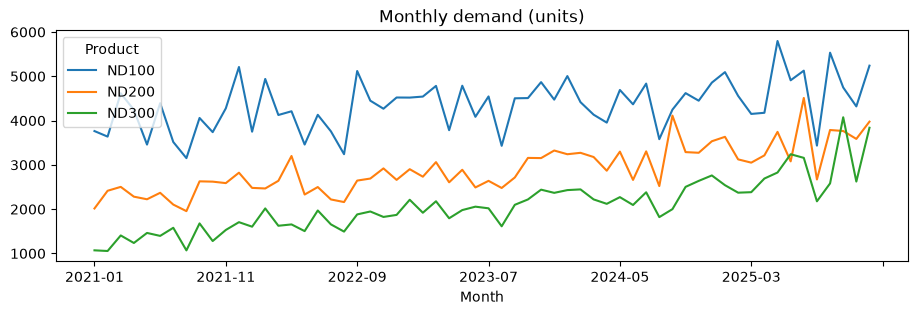

In [3]:
print("Demand history (last rows):")
show(history.tail(6), decimals=3)
print("January–March 2026 plan:")
show(plan_q1, decimals=3)
demand = history.pivot(index="Month", columns="Product", values="Demand_Units")
demand.plot(figsize=(11, 3), title="Monthly demand (units)")
plt.show()

Two rows in Kerem's plan matter: the January Pro promotion is `approved`, the March Standard
promotion is `pending`. The chart shows growth, recurring ups and downs and spikes in promotion
months, all of which the model has to explain.

## 1 · Demand forecast

The question: forecast January–March demand by product as of 31 December, and show why the forecast
can be trusted. Ece set the boundary: “We'll forecast as of today, 31 December 2025, using only what
we know today.”

We judged models on two measures:

$$\text{WAPE}=\frac{\sum|\text{actual}-\text{forecast}|}{\sum \text{actual}},\qquad \text{Bias}=\frac{\sum(\text{forecast}-\text{actual})}{\sum \text{actual}}$$

WAPE measures the size of the error, with no cancelling between over- and under-forecasts. Bias is
signed: positive means forecasting too high, negative too low. Both matter for planning; persistent
over-forecasting builds stock, persistent under-forecasting loses orders.

In [4]:
# READY · Forecast tools

def wape(actual, forecast):
    """WAPE: total absolute error over total actual demand. Lower is better."""
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return np.abs(actual - forecast).sum() / actual.sum()


def bias(actual, forecast):
    """Bias: (total forecast − total actual) / total actual. Positive means over-forecasting,
    negative under-forecasting."""
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return (forecast - actual).sum() / actual.sum()


def seasonal_naive(train, test):
    """Benchmark: the same month last year."""
    return test["lag12"].to_numpy(float)


def check_backtest(backtest):
    """Runs your backtest on the benchmark and compares it with the correct result."""
    problems = set()

    def probe(train, test):
        if len(train) and train.t.max() >= test.t.min():
            problems.add("future")
        if "Demand_Units" in test.columns:
            problems.add("actuals")
        return seasonal_naive(train, test)

    bt = backtest(probe)
    if len(bt) == 0:
        print("The backtest returns nothing yet.")
    elif "future" in problems:
        print("✗ At some origins the model also sees data from after the months it is forecasting.")
    elif "actuals" in problems:
        print("✗ test still has the Demand_Units column, so the model can see the actuals. Drop "
              "it before calling the model: test.drop(columns='Demand_Units').")
    else:
        w, b = wape(bt.Demand_Units, bt.Forecast), bias(bt.Demand_Units, bt.Forecast)
        if len(bt) == 72 and abs(w - NAIVE_WAPE) < 0.0005 and abs(b - NAIVE_BIAS) < 0.0005:
            print(f"✓ Your time split is correct: {len(bt)} forecasts, seasonal naive WAPE "
                  f"{pct(w)}, bias {pct(b, signed=True)}.")
        else:
            print("✗ For seasonal naive, a correct backtest gives 72 forecasts, WAPE "
                  f"{pct(NAIVE_WAPE)} and bias {pct(NAIVE_BIAS, signed=True)}. Yours: {len(bt)} "
                  f"forecasts, WAPE {pct(w)}, bias {pct(b, signed=True)}.")


def compare(models, backtest):
    """Backtests every model and shows WAPE, bias and bias by product."""
    rows = {}
    for name, model in models.items():
        bt = backtest(model)
        if len(bt) == 0:
            print("The backtest returns nothing yet.")
            return
        w = wape(bt.Demand_Units, bt.Forecast)
        rows[name] = {"WAPE": pct(w), "Bias": pct(bias(bt.Demand_Units, bt.Forecast), signed=True)}
        for p, g in bt.groupby("Product"):
            rows[name][f"Bias {p}"] = pct(bias(g.Demand_Units, g.Forecast), signed=True)
        if w < 0.01:
            print(f"⚠ {name}: WAPE {pct(w)}. An error this low usually means the model can see "
                  "the actuals; check for leakage.")
    display(pd.DataFrame.from_dict(rows, orient="index"))


def plot_forecast(history, forecast):
    """Plots past demand and the January–March 2026 forecast by product on one chart (forecast
    dashed)."""
    past = history.pivot(index="Month", columns="Product", values="Demand_Units")
    ahead = forecast.pivot(index="Month", columns="Product", values="Forecast_Units")
    ahead = pd.concat([past.tail(1), ahead])         # start the dashed lines from December 2025
    past.index = pd.PeriodIndex(past.index, freq="M")
    ahead.index = pd.PeriodIndex(ahead.index, freq="M")
    ax = past.plot(figsize=(11, 3.5), title="Monthly demand and the January–March 2026 forecast "
                                            "(units)")
    colours = [line.get_color() for line in ax.get_lines()]
    ahead.plot(ax=ax, style="--", color=colours, legend=False)
    return ax

### Step 1.1 · The backtest

The ground rules set the backtest: eight origins, every three months from December 2023 to September
2025. At each origin the model sees data up to and including that month and forecasts the next
three: 8 × 3 months × 3 products = 72 forecasts.

We split by time because the error we measure should match the error we will face in use; a random
split lets the model see the future and flatters it. For the same reason `Demand_Units` is dropped
from `test`. Working days, prices and promotions stay visible, since in the past they were fixed at
least three months ahead.

In [5]:
# the eight origins from the ground rules
ORIGINS = ["2023-12", "2024-03", "2024-06", "2024-09", "2024-12", "2025-03", "2025-06", "2025-09"]


def backtest(model):
    """Backtest. Returns one row per forecast: Month, Product, Demand_Units and Forecast."""
    results = []
    for origin in ORIGINS:
        # the origin as a month number
        last = pd.Period(origin, freq="M").ordinal
        # everything up to and including the origin
        train = history[history.t <= last]
        # the next three months, and nothing later
        test = history[(history.t > last) & (history.t <= last + 3)]
        # the model never sees the actuals
        forecast = model(train, test.drop(columns="Demand_Units"))
        rows = test[["Month", "Product", "Demand_Units"]]
        results.append(rows.assign(Forecast=np.asarray(forecast, float), Origin=origin))
    if not results:
        return pd.DataFrame(columns=["Month", "Product", "Demand_Units", "Forecast"])
    return pd.concat(results)

In [6]:
check_backtest(backtest)

✓ Your time split is correct: 72 forecasts, seasonal naive WAPE 10.7%, bias −8.6%.


72 forecasts; the seasonal naive benchmark scores a WAPE of 10.7% and a bias of −8.6%. The bias is
negative because repeating last year's figure always trails a growing series by a year. Every model
has to beat both numbers.

### Step 1.2 · Our model

We took demand to depend on three things. Trend: all three products grow as data halls open. Working
days: religious holidays move between months (Eid al-Fitr fell in May in 2021 and falls in March in
2026), so the calendar month does not say how many days the plant works. Price: promotions range
from 5% to 15% off; the `Promo` flag does not know the depth, the ratio of price to list price does.

We fitted a log-linear regression per product:

$$\log(\text{demand}) = a + b\,t + \beta\,\log(\text{working days}) + \varepsilon\,\log\frac{\text{price}}{\text{list price}}$$

Effects are multiplicative and β and ε are elasticities. We transformed back with `exp(ŷ + σ²/2)`,
because `exp(ŷ)` gives the median, not the mean. We tried both the full 60 months and the latest 36,
and added Holt-Winters and a month-dummy regression for comparison.

In [7]:
def log_regression(train, test, features, window=None):
    """Regression on log demand, fitted per product by least squares.
    features(df) returns the explanatory columns; window: number of latest training months to
    use (None = all)."""
    out = pd.Series(index=test.index, dtype=float)
    for p in PRODUCTS:
        tr, te = train[train.Product == p], test[test.Product == p]
        if window:
            tr = tr[tr.t > tr.t.max() - window]
        y = np.log(tr.Demand_Units)
        coef, *_ = np.linalg.lstsq(features(tr), y, rcond=None)
        residual_var = np.var(y - features(tr) @ coef)
        # transform back from logs, with the lognormal bias correction
        out[te.index] = np.exp(features(te) @ coef + residual_var / 2)
    return out.to_numpy()


def drivers(df):
    """log(demand) = a + b·t + β·log(working days) + ε·discount (discount = log(price / list
    price)): four coefficients per product."""
    return np.column_stack([np.ones(len(df)), df.t, np.log(df.Working_Days), df.discount])


def my_model(train, test):
    """Reference: the driver regression on the latest 36 months."""
    return log_regression(train, test, drivers, window=36)

The comparison models: Holt-Winters, a regression on month dummies and the promotion flag, and the
driver regression fitted on all 60 months.

In [8]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def holt_winters(train, test):
    """Holt-Winters: additive trend, multiplicative twelve-month seasonality. Uses demand only."""
    out = pd.Series(index=test.index, dtype=float)
    for p in PRODUCTS:
        tr, te = train[train.Product == p].sort_values("t"), test[test.Product == p]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            series = tr.Demand_Units.to_numpy(float)
            model = ExponentialSmoothing(series, trend="add", seasonal="mul", seasonal_periods=12)
            fit = model.fit()
        ahead = fit.forecast(int(te.t.max() - tr.t.max()))
        out[te.index] = [ahead[int(t - tr.t.max() - 1)] for t in te.t]
    return out.to_numpy()


def month_dummies(df):
    """log(demand) = a + b·t + c·promotion flag + 11 month dummies: 14 coefficients per product."""
    dummies = [(df.month == m).astype(float) for m in range(2, 13)]
    return np.column_stack([np.ones(len(df)), df.t, df.Promo] + dummies)


def with_month_dummies(train, test):
    return log_regression(train, test, month_dummies)


def drivers_all_history(train, test):
    return log_regression(train, test, drivers)

In [9]:
compare({"Seasonal naive": seasonal_naive,
         "Holt-Winters": holt_winters,
         "Month dummies + promotion flag": with_month_dummies,
         "Drivers, all history": drivers_all_history,
         "My model": my_model}, backtest)

,WAPE,Bias,Bias ND100,Bias ND200,Bias ND300
Seasonal naive,10.7%,−8.6%,−3.9%,−9.9%,−15.5%
Holt-Winters,9.4%,−1.3%,+0.0%,−2.6%,−2.1%
Month dummies + promotion flag,9.2%,+2.3%,+1.3%,+0.4%,+6.3%
"Drivers, all history",5.2%,+2.2%,+1.1%,−0.3%,+7.6%
My model,5.1%,+1.1%,+0.7%,+0.7%,+2.3%


Holt-Winters (9.4%) and the month-dummy regression (9.2%) beat the benchmark only narrowly; neither
knows a month's working days or the depth of a discount. With the drivers the error falls to around
5%, so most of the apparent seasonality comes from the calendar and promotions.

Bias by product settled the choice. The 60-month model looks good overall (5.2%) but over-forecasts
Pro by +7.6%: Pro's growth is slowing, and a constant growth rate fitted to five years carries the
early pace forward. The 36-month model keeps the same overall error (5.1%) and cuts Pro's bias to
+2.3%. That is our reference model.

One limitation: we chose the window on the same backtest, so 5.1% is slightly optimistic (selection
bias).

Common mistakes: using `history` instead of `train` inside the model, not transforming a log model
back with `exp`, and looking only at total WAPE and missing the Pro bias. Tree models cannot
extrapolate a trend, so they under-forecast a growing series; with the trend removed first, our trials put them at around 8%.

### Step 1.3 · The January–March 2026 forecast

The 2026 values are in Kerem's plan, which hides a trap: “The January Pro promotion has been
approved. The March promotion for Standard is still awaiting approval; I've put it in the plan for
now, and if it goes ahead, March will be strong.”

On 31 December the March promotion is not settled. Including it in the base forecast would mean
acting as if we knew the outcome; this is not data leakage, since no future data enters the model,
but treating unsettled information as settled. We built the base forecast without it and show the
promotion as a separate scenario. The approved January promotion stays in.

Our model reads the discount, not `Promo`, so setting `Promo = 0` is not enough: the price goes back
to the regular planned price (€112.57) and `add_features` recomputes `discount`.

In [10]:
future = plan_q1.copy()
# still awaiting approval on 31 December: not settled, so the base forecast leaves it out
late = future.Promo_Status == "pending"
regular = future[future.Promo == 0].groupby("Product").Planned_Price_EUR.first()
future.loc[late, "Planned_Price_EUR"] = future.loc[late, "Product"].map(regular)
future.loc[late, "Promo"] = 0
future = add_features(future)          # recomputes discount from the new price

forecast = future.assign(Forecast_Units=my_model(history, future))
shown = ["Month", "Product", "Promo", "Planned_Price_EUR", "Forecast_Units"]
show(forecast[shown].round({"Forecast_Units": 0}))

,Month,Product,Promo,Planned_Price_EUR,Forecast_Units
0,2026-01,ND100,0,112.57,"4,678"
1,2026-01,ND200,0,146.34,"3,680"
2,2026-01,ND300,1,176.07,"3,228"
3,2026-02,ND100,0,112.57,"4,454"
4,2026-02,ND200,0,146.34,"3,544"
5,2026-02,ND300,0,191.38,"2,765"
6,2026-03,ND100,0,112.57,"4,693"
7,2026-03,ND200,0,146.34,"3,737"
8,2026-03,ND300,0,191.38,"2,918"


In [11]:
# for comparison: Kerem's plan used as it stands
as_planned = plan_q1.assign(Forecast_Units=my_model(history, plan_q1))
march = (forecast.Month == "2026-03") & (forecast.Product == "ND100")
base = forecast.loc[march, "Forecast_Units"].item()
promo = as_planned.loc[march, "Forecast_Units"].item()
print(f"March ND100 | base forecast (no promotion): {fmt(base)} | with the pending promotion: "
      f"{fmt(promo)} | difference: {fmt(promo - base)} units")

March ND100 | base forecast (no promotion): 4,693 | with the pending promotion: 5,547 | difference: 854 units


The base forecast for Standard in March is 4,693 units; using the plan unchanged would give 5,547.
The difference of 854 units is about 18% of the base forecast. Pro's high January figure comes from
the approved promotion.

Past demand and the forecast (dashed).

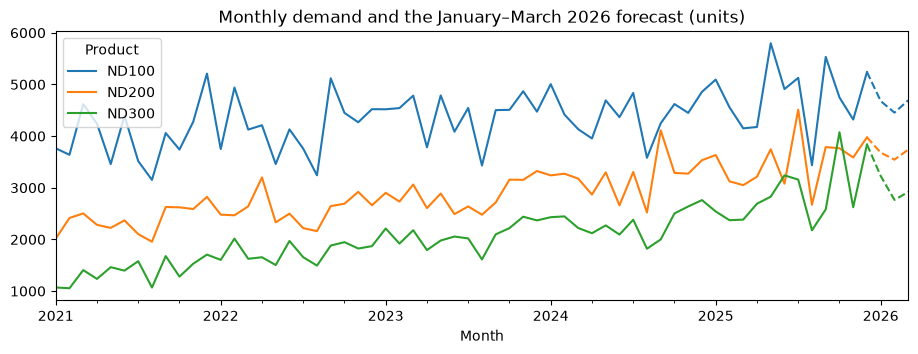

In [12]:
plot_forecast(history, forecast)
plt.show()

## 2 · Production plan and takt

At minute 45 Deniz's consensus plan arrived, and everyone planned from the same demand. Deniz asked:
“Which month puts the line under the most pressure? How many stations do we need? Will the current
layout cope?” This part answers the first; Part 3 the other two.

In [13]:
# READY · Planning tools

def unlock_release(file, password):
    """Unpacks a password-protected file into the release/ folder next to the notebook."""
    if not password:
        print("Type the password announced in the room and run the cell again.")
        return
    password = "-".join(password.lower().split())      # works with capitals or spaces too
    with zipfile.ZipFile(file) as z:
        for member in z.infolist():
            try:
                z.extract(member, ".", pwd=password.encode())
            except RuntimeError:
                print("Wrong password, try again.")
                return
            except (zipfile.BadZipFile, zlib.error):
                Path(member.filename).unlink(missing_ok=True)       # remove the half-written file
                print("Wrong password, try again.")
                return
        print("Unpacked:", ", ".join(n for n in z.namelist() if not n.endswith("/")))


def load_consensus():
    """Returns the consensus demand as a {(month, product): units} dictionary."""
    if not (RELEASE / "consensus_demand.csv").exists():
        print("Unlock the minute-45 file first.")
        return {}
    demand = pd.read_csv(RELEASE / "consensus_demand.csv")
    show(demand.pivot(index="Month", columns="Product", values="Consensus_Demand_Units"))
    return {(r.Month, r.Product): r.Consensus_Demand_Units for r in demand.itertuples()}


def add_urgent(D):
    """Adds the URGENT order to the consensus demand D and returns the new dictionary."""
    if not D:
        print("Unlock the minute-45 file first.")
        return {}
    if not (RELEASE / "urgent_order.csv").exists():
        print("Unlock the minute-95 file first.")
        return dict(D)
    urgent = pd.read_csv(RELEASE / "urgent_order.csv")
    show(urgent)
    out = dict(D)
    for r in urgent.itertuples():
        out[(r.Month, r.Product)] += r.Additional_Units
    return out


def _mark(ok):
    return "✓" if ok else "✗"


# the placeholder product mix suggested in the introduction
INTRO_MIX = [0.4, 0.35, 0.25]


def _intro_mix(mix):
    """True if the product mix is still the placeholder from the introduction."""
    return bool(mix) and [mix.get(p) for p in PRODUCTS] == INTRO_MIX


def check_plan(avail, plan, takt=None, design_month=None, C=None, mix=None):
    """Compares your January numbers with the correct ones and checks that DESIGN_MONTH, C and MIX
    fit together."""
    avail, takt, mix = _as_dict(avail), _as_dict(takt) or {}, _as_dict(mix)
    if not avail or plan is None or len(plan) == 0:
        print("available_time() and production_plan() return nothing yet.")
        return
    jan_planned = plan[plan.Month == "2026-01"].Planned_Production.sum()
    ok = abs(avail.get("2026-01", 0) - JAN_AVAILABLE) < 1
    print(_mark(ok), f"January available time (correct: {fmt(JAN_AVAILABLE)} s)")
    ok = abs(jan_planned - JAN_PLANNED) <= 3
    print(_mark(ok), f"January planned production, all products (correct: {fmt(JAN_PLANNED)} "
                     "units)")
    if takt:
        ok = abs(takt.get("2026-01", 0) - JAN_TAKT) < 0.03
        print(_mark(ok), f"January takt time (correct: {fmt(JAN_TAKT, 2)} s)")
    if C is not None or mix:
        design_takt = takt.get(design_month)
        ok = (bool(mix) and abs(sum(mix.values()) - 1) < 1e-6
              and C is not None and design_takt is not None and abs(C - design_takt) < 0.01)
        print(_mark(ok), "MIX adds up to 1 and C equals the takt of DESIGN_MONTH (this doesn't "
                         "check which month you picked)")
    if _intro_mix(mix):
        print("⚠ MIX is still the placeholder suggested in the introduction. Use the product mix "
              "you worked out in Part 2.")

### Step 2.1 · Unlocking the file

The password is `navy-crane`. Deniz's email gives the method: closing stock of 10% of next month's
demand, units failing the first test scrapped, and “calculate takt from this planned production,
scrap included” (strictly, a planned cycle time). The plan includes April because March's closing
stock depends on it.

In [14]:
unlock_release(CASE_FILES / "release_45_min.zip", password="navy-crane")
D = load_consensus()   # {(month, product): consensus demand}

Unpacked: release/consensus_demand.csv, release/Deniz_Email_45_min.pdf


Product,ND100,ND200,ND300
Month,,,
2026-01,"4,759","3,699","3,241"
2026-02,"4,568","3,568","2,690"
2026-03,"4,787","3,758","2,833"
2026-04,"4,802","3,789","2,855"


### Step 2.2 · Available time and planned production

A working day gives 2 × (7.5 − 0.5) − 0.25 = 13.75 hours; January gives 21 × 13.75 × 3,600 =
1,039,500 s.

February needs Hasan's message: “It's being replaced in February, so the line will be down for two
working days.” The calendar records this as `Additional_Stop_Hours` = 27.5. February: (20 × 13.75 −
27.5) × 3,600 = 891,000 s. Teams that missed the column saw February as roomier than it is, and the
check cell, which only looks at January, did not catch it.

Planned production, by product and month:

$$\text{planned production} = \frac{\text{demand} + \text{closing stock} - \text{opening stock}}{\text{first-pass yield}}$$

Opening stock is the previous month's closing stock, the 31 December stock for January; round up
only at the end. ND100 in January: (4,759 + 0.10 × 4,568 − 780) / 0.985 = 4,503.4 → 4,504. Dividing
by the yield covers scrap; inflating the task times as well would count it twice.

In [15]:
def available_time(calendar):
    """Returns each month's available time in seconds: {month: seconds}."""
    hours_per_shift = calendar.Hours_per_Shift - calendar.Break_Hours_per_Shift
    net_hours = calendar.Shifts_per_Day * hours_per_shift - calendar.Daily_Maintenance_Hours
    seconds = (calendar.Working_Days * net_hours - calendar.Additional_Stop_Hours) * 3600
    return dict(zip(calendar.Month, seconds))


def production_plan(D):
    """Returns one row per month and product: Month, Product and Planned_Production."""
    stock, rows = products.set_index("Product"), []
    for p in PRODUCTS:
        opening = stock.loc[p, "Inventory_2025_12_31"]
        for k, m in enumerate(MONTHS):
            next_month = (MONTHS + ["2026-04"])[k + 1]
            # closing stock: 10% of next month's demand
            closing = 0.10 * D[(next_month, p)]
            needed = (D[(m, p)] + closing - opening) / stock.loc[p, "First_Pass_Yield"]
            rows.append(dict(Month=m, Product=p, Planned_Production=math.ceil(needed - 1e-9)))
            # this month's closing stock opens next month
            opening = closing
    return pd.DataFrame(rows)


avail, plan = available_time(calendar), production_plan(D)

In [16]:
show(plan.pivot(index="Month", columns="Product", values="Planned_Production"))

Product,ND100,ND200,ND300
Month,,,
2026-01,"4,504","3,517","3,159"
2026-02,"4,660","3,661","2,774"
2026-03,"4,862","3,838","2,908"


January needs 11,180 units, below its demand of 11,699 because the year closed with surplus stock.
March has the most production (11,608). Common mistakes: using the 31 December stock as every
month's opening stock (January passes, February and March are wrong) and multiplying by the yield
instead of dividing.

### Step 2.3 · Takt time and the design month

Takt = available time / planned production. Selin decides the design month: “It will run with one
layout from January to March; we won't change it mid-quarter.” One layout must cover all three
months, so the month with the shortest takt decides, not the one with the most demand or production.
The mix comes from that month's plan, and `C` stays unrounded.

In [17]:
def units_of(plan, month):
    return plan[plan.Month == month].set_index("Product").Planned_Production


def mix_of(plan, month):
    """Product mix {product: share} of the planned production in a month."""
    units = units_of(plan, month)
    return (units / units.sum()).to_dict()


planned = plan.groupby("Month").Planned_Production.sum()
takt = {m: avail[m] / planned[m] for m in MONTHS}
show(pd.DataFrame({"Planned production": planned, "Available time (s)": pd.Series(avail),
                   "Takt (s)": pd.Series(takt)}))

# the line runs unchanged all quarter, so the shortest takt decides
DESIGN_MONTH = min(takt, key=takt.get)
C, MIX = takt[DESIGN_MONTH], mix_of(plan, DESIGN_MONTH)
print(f"Design month: {DESIGN_MONTH} | C = {fmt(C, 2)} s | MIX:",
      ", ".join(f"{p} {fmt(v, 3)}" for p, v in MIX.items()))

,Planned production,Available time (s),Takt (s)
2026-01,"11,180","1,039,500",92.98
2026-02,"11,095","891,000",80.31
2026-03,"11,608","1,039,500",89.55


Design month: 2026-02 | C = 80.31 s | MIX: ND100 0.420, ND200 0.330, ND300 0.250


In [18]:
check_plan(avail, plan, takt, DESIGN_MONTH, C, MIX)

✓ January available time (correct: 1,039,500 s)
✓ January planned production, all products (correct: 11,180 units)
✓ January takt time (correct: 92.98 s)
✓ MIX adds up to 1 and C equals the takt of DESIGN_MONTH (this doesn't check which month you picked)


Takt: 92.98 s in January, 80.31 s in February, 89.55 s in March. February is the design month; 20
working days and the two-day stop make it the tightest. A team that missed the stop would get 89.23
s and think six stations enough. February's mix: 0.42 Standard, 0.33 Plus, 0.25 Pro. The check cell
does not test which month you chose; that was left to the teams on purpose.

## 3 · Line balancing

The question: a layout that runs at February's takt (80.31 s) all quarter. Selin's priorities: “keep
the number of stations as low as you can. If there's more than one layout with that many stations,
give me the best-balanced one.” The referee (`check_assignment`) checks only the basics; the rules
in the messages are not in it.

In [19]:
# READY · Line tools

def weighted(mix):
    """Weighted task times for a product mix {product: share}."""
    mix = dict(mix)
    return {i: sum(mix[p] * TIME[i][p] for p in PRODUCTS) for i in TASKS}


def station_loads(line, mix):
    """For each station: its tasks, weighted load, time per product and process groups, at full
    precision."""
    w, out = weighted(mix), {}
    for task, k in sorted(dict(line).items()):
        if task not in TIME:
            continue
        if k not in out:
            out[k] = {"Tasks": [], "Load": 0.0, "Groups": set(), **{p: 0 for p in PRODUCTS}}
        s = out[k]
        s["Tasks"].append(task)
        s["Load"] += w[task]
        s["Groups"].add(GROUP[task])
        for p in PRODUCTS:
            s[p] += TIME[task][p]
    return dict(sorted(out.items()))


def station_table(line, mix):
    """One row per station: tasks, weighted load, time per product and process groups (loads
    rounded for display)."""
    rows = {k: {"Tasks": ", ".join(s["Tasks"]), "Weighted": round(s["Load"], 2),
                **{p: s[p] for p in PRODUCTS}, "Groups": ", ".join(sorted(s["Groups"]))}
            for k, s in station_loads(line, mix).items()}
    return pd.DataFrame.from_dict(rows, orient="index")


def check_assignment(line, C, mix):
    """The referee: checks only the basics of a line {task: station}: every task at one station,
    the sequence, the takt and the station numbers. An empty list means no problem with these;
    it doesn't look at the rules in the messages."""
    line = dict(line)
    issues = [f"{i} isn't assigned to any station." for i in TASKS if i not in line]
    issues += [f"There's no task called {i}." for i in line if i not in TIME]
    issues += [f"Sequence broken: {a} (station {line[a]}) must come before {b} (station {line[b]})."
               for a, b in ARCS if a in line and b in line and line[a] > line[b]]
    stations = sorted(set(line.values()))
    if stations != list(range(1, len(stations) + 1)):
        issues.append("Stations must be numbered from 1 with no gaps (current numbers: "
                      f"{stations}).")
    for k, s in station_loads(line, mix).items():
        if s["Load"] > C + 1e-9:
            issues.append(f"Station {k}: {fmt(s['Load'], 2)} s > takt {fmt(C, 2)} s")
    return issues


def capacity(line, mix, seconds):
    """Units the line can make in the given time (seconds)."""
    loads = station_loads(line, mix)
    if not loads:
        return 0
    busiest = max(s["Load"] for s in loads.values())
    return math.floor(seconds / busiest)


def _own_rules(rules, line, C, mix):
    """Runs your rules function and returns what it found as a list."""
    found = rules(line, C, mix)
    if found is None:
        print("Note: check_rules didn't return a list (it returned None), so your rules weren't "
              "checked. The function should end with return problems.")
    return list(found or [])


def _report(line, C, mix, rules=None):
    issues = check_assignment(line, C, mix)
    print("Referee (basic rules):" + ("" if issues else " no problems"))
    for issue in issues:
        print("  -", issue)
    if rules is None:
        print("The referee skips the rules in the messages: pass rules=check_rules.")
        return
    problems = _own_rules(rules, line, C, mix)
    print("Your rules (check_rules):" + ("" if problems else " no problems found"))
    for problem in problems:
        print("  -", problem)


def show_current_line(C, mix, rules=None):
    """Shows the current line and asks the referee and, if given, your own rules."""
    mix = _as_dict(mix)
    if C is None or not mix:
        print("Set C and MIX in Part 2 first, or try placeholders for now: C, MIX = 85, "
              "{'ND100': 0.4, 'ND200': 0.35, 'ND300': 0.25}")
        return
    print("Current line, at your takt and mix:")
    show(station_table(CURRENT_LINE, mix))
    _report(CURRENT_LINE, C, mix, rules)


def report_line(line, C, mix, plan, takt, bound=None, rules=None):
    """Shows the stations, asks the referee and, if given, your own rules, and tests the line in
    all three months."""
    mix, takt = _as_dict(mix), _as_dict(takt)
    if C is None or not mix:
        print("Set C and MIX in Part 2 first, or try placeholders for now: C, MIX = 85, "
              "{'ND100': 0.4, 'ND200': 0.35, 'ND300': 0.25}")
        return
    if line is None:
        print("The model found no feasible line (balance_line returned None). Check your "
              "constraints and C.")
        return
    line = dict(line)
    if not line:
        print("No line yet: balance_line returns an empty dictionary.")
        return
    table = station_table(line, mix)
    show(table)
    lower = bound(C, mix) if bound else None
    print(f"Stations: {len(table)} | lower bound: {'—' if lower is None else lower} | "
          f"busiest station: {fmt(table.Weighted.max(), 2)} s | takt: {fmt(C, 2)} s")
    _report(line, C, mix, rules)
    if plan is not None and len(plan) and takt and all(m in takt for m in MONTHS):
        print("All three months, each at its own takt and mix:")
        for m in MONTHS:
            units = plan[plan.Month == m].set_index("Product").Planned_Production
            mix_m = (units / units.sum()).to_dict()
            issues = check_assignment(line, takt[m], mix_m)
            if rules is not None:
                issues += _own_rules(rules, line, takt[m], mix_m)
            lower = bound(takt[m], mix_m) if bound else None
            shown = "" if lower is None else f"lower bound {lower} | "
            print(" ", m, shown + ("no problems" if not issues else "; ".join(issues)))

### Step 3.1 · The line's rules, and today's line

None of the rules were in the data; all came from the messages:

- One station per task, sequence kept. Hasan: “we can't split a task across two stations”, “No shaft
  alignment before the rotor is in”. The referee checks these.
- A single product's station time may exceed takt by at most 20%: “when the same product comes
  through back to back, the operator can absorb a station time up to 20% over takt using the buffer;
  anything more piles up.”
- At most two kinds of work (`Process_Group`) per station, from the quality audit.
- Power terminal wiring (T09) and thermal compound (T10) not at the same station.
- Nine stations at most. Selin: “A tenth would mean knocking down a wall.”

We applied the 20% rule to each product's own time, not the weighted load. The weighted load is the
average pace; Hasan describes Pros arriving back to back: “Fine on average, they say, but not at the
station.” Limits are written in terms of `C` (`1.2 * C`) because the same line is also tested at
January's and March's takt.

In [20]:
MAX_STATIONS = 9                      # Selin: room for nine stations at most
OVERLOAD = 1.2                        # Hasan: a single product may run at most 20% over takt
MAX_GROUPS = 2                        # Hasan (quality audit): two kinds of work per station at most
# Hasan (quality audit): power terminal wiring and thermal compound apart
INCOMPATIBLE = [("T09", "T10")]


def check_rules(line, C, mix):
    """The line rules you found in the messages. Add a short description to problems for every case
    that breaks a rule; an empty list means no problems were found."""
    problems = []
    if line and max(line.values()) > MAX_STATIONS:
        problems.append("Selin: that many stations won't fit on the floor.")
    for k, s in station_loads(line, mix).items():
        problems += [f"Hasan: work piles up at station {k} when {p} units come through in a row. "
                     "The operator can't absorb that much."
                     for p in PRODUCTS if s[p] > OVERLOAD * C + 1e-9]
        if len(s["Groups"]) > MAX_GROUPS:
            groups = ", ".join(sorted(s["Groups"]))
            problems.append(f"Quality auditor: station {k} mixes too many kinds of work "
                            f"({groups}).")
        problems += [f"Quality auditor: {a} and {b} are done at the same bench at station {k}."
                     for a, b in INCOMPATIBLE if a in s["Tasks"] and b in s["Tasks"]]
    return problems

In [21]:
show_current_line(C, MIX, rules=check_rules)

Current line, at your takt and mix:


,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06",72.40,68,73,79,"Electrical, Mechanical"
2,"T02, T07, T08",76.73,72,78,83,"Electrical, Mechanical"
3,"T03, T04",60.57,56,60,69,Mechanical
4,"T05, T11",61.32,58,62,66,"Electrical, Mechanical"
5,"T09, T10, T13",82.95,69,84,105,"Electrical, Mechanical, Software/Test"
6,"T12, T14",76.40,72,77,83,"Mechanical, Software/Test"
7,"T15, T16, T17",69.40,66,71,73,"Packaging, Software/Test"


Referee (basic rules):
  - Station 5: 82.95 s > takt 80.31 s
Your rules (check_rules):
  - Hasan: work piles up at station 5 when ND300 units come through in a row. The operator can't absorb that much.
  - Quality auditor: station 5 mixes too many kinds of work (Electrical, Mechanical, Software/Test).
  - Quality auditor: T09 and T10 are done at the same bench at station 5.


Station 5 (T09, T10, T13) has four problems: weighted load 0.42 × 69 + 0.33 × 84 + 0.25 × 105 =
82.95 s > 80.31 s; Pro at 105 s > 1.2 × 80.31 = 96.37 s; three kinds of work; T09 and T10 on one
bench. Stations 3 and 4 sit near 60 s, idle a quarter of each cycle. Total work (about 500 s) fits
in 7 × 80.31 = 562 s, so the problem is largely distribution. Deniz's third question: the current
layout cannot cope with February.

Teams still using the placeholder `C = 85` got no warning (82.95 < 85) and thought the current line
was fine.

### Step 3.2 · Lower bound and optimisation model

Lower bound = ⌈total weighted work / takt⌉. It rules out fewer stations; it does not promise that
this many will do.

The MILP's variables: `x[i][k]` (task i at station k), `y[k]` (station open), `z[g][k]` (station k
has work of kind g), `peak` (load of the busiest station). Selin's two goals are combined into one
objective by weighting:

$$\min\; 1000 \cdot \sum_k y_k + \text{peak}$$

This is a weighted lexicographic objective: since `peak` cannot exceed takt (about 80 s), no gain in
balance can make up for a station (1,000). `peak` is constrained to be at least every station's
load; the objective pushes it down to the busiest one.

Precedence uses station numbers: Σ k · x[a][k] ≤ Σ k · x[b][k]. Equality is allowed, because “two
tasks that follow each other can share a station, as long as the later task doesn't end up at an
earlier station.” Teams that wrote `x[a][k] <= x[b][k]` forced both tasks onto one station. Two
kinds of work: `x[i][k] ≤ z[g(i)][k]` and Σ z ≤ 2 per station.

In [22]:
def lower_bound(C, mix):
    """Lower bound on the number of stations (prep note)."""
    return math.ceil(sum(weighted(mix).values()) / C - 1e-9)


def balance_line(C, mix, stations=None):
    """Builds and solves the line model. Returns {task: station}, or None if no line exists.
    stations=m fixes the number of stations at m and only balances (for the comparison at
    the end of Step 3.2)."""
    w = weighted(mix)                                  # weighted task times
    model = pulp.LpProblem("line", pulp.LpMinimize)
    K = range(1, (stations or MAX_STATIONS) + 1)
    groups = sorted(set(GROUP.values()))

    # decision variables
    # x[i][k] = 1: task i is at station k
    x = pulp.LpVariable.dicts("x", (TASKS, K), cat="Binary")
    # y[k] = 1: station k is open
    y = pulp.LpVariable.dicts("y", K, cat="Binary")
    # z[g][k] = 1: process group g is present at station k
    z = pulp.LpVariable.dicts("z", (groups, K), cat="Binary")
    # load of the busiest station
    peak = pulp.LpVariable("peak", lowBound=0)

    # stations first, balance second: the busiest load is always under 1000 s, so no gain in balance
    #   can outweigh an extra station
    model += 1000 * pulp.lpSum(y[k] for k in K) + peak

    # L1 every task at exactly one station
    for i in TASKS:
        model += pulp.lpSum(x[i][k] for k in K) == 1
    # L2 Hasan: keep the sequence
    for a, b in ARCS:
        model += pulp.lpSum(k * x[a][k] for k in K) <= pulp.lpSum(k * x[b][k] for k in K)
    for k in K:
        load = pulp.lpSum(w[i] * x[i][k] for i in TASKS)
        # L3 weighted load within takt
        model += load <= C * y[k]
        # peak is at least as large as every station's load
        model += load <= peak
        # L4 Hasan: at most 20% over, per product
        for p in PRODUCTS:
            model += pulp.lpSum(TIME[i][p] * x[i][k] for i in TASKS) <= OVERLOAD * C
        # L5 Selin: nine stations at most, no gaps
        if k > 1:
            model += y[k] <= y[k - 1]
        # exactly this many stations, none of them empty
        if stations:
            model += y[k] == 1
            model += pulp.lpSum(x[i][k] for i in TASKS) >= 1
        # L6 quality: two process groups at most
        for i in TASKS:
            model += x[i][k] <= z[GROUP[i]][k]
        model += pulp.lpSum(z[g][k] for g in groups) <= MAX_GROUPS
        # L7 quality: thermal compound apart from power terminals
        for a, b in INCOMPATIBLE:
            model += x[a][k] + x[b][k] <= 1

    model.solve(SOLVER)
    if pulp.LpStatus[model.status] != "Optimal":
        return None
    return {i: k for i in TASKS for k in K if x[i][k].value() > 0.5}

In [23]:
work = sum(weighted(MIX).values())
print(f"Total weighted work: {fmt(work, 2)} s | {fmt(work, 2)} / {fmt(C, 2)} = {fmt(work / C, 2)}"
      f" → lower bound {lower_bound(C, MIX)}")

Total weighted work: 499.77 s | 499.77 / 80.31 = 6.22 → lower bound 7


In [24]:
new_line = balance_line(C, MIX) if C is not None and MIX is not None else None
report_line(new_line, C, MIX, plan, takt, bound=lower_bound, rules=check_rules)

,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06",72.40,68,73,79,"Electrical, Mechanical"
2,"T03, T08",75.81,69,76,87,"Electrical, Mechanical"
3,"T02, T07, T09",77.73,70,76,93,"Electrical, Mechanical"
4,"T04, T05, T10",68.30,62,72,74,Mechanical
5,"T11, T13",59.73,54,60,69,"Electrical, Software/Test"
6,"T12, T14",76.40,72,77,83,"Mechanical, Software/Test"
7,"T15, T16, T17",69.40,66,71,73,"Packaging, Software/Test"


Stations: 7 | lower bound: 7 | busiest station: 77.73 s | takt: 80.31 s
Referee (basic rules): no problems
Your rules (check_rules): no problems found
All three months, each at its own takt and mix:
  2026-01 lower bound 6 | no problems
  2026-02 lower bound 7 | no problems
  2026-03 lower bound 6 | no problems


Lower bound: 499.77 / 80.31 = 6.22 → 7. The model finds a 7-station line with a busiest station of
77.73 s; the referee and `check_rules` find nothing, and January and March pass too. As the solver
proves optimality, no valid 7-station layout gets below 77.73 s. Deniz's second question: 7
stations. Your assignment may differ; scoring looked at validity, station count and the busiest
station.

A model without the second goal returns any 7-station line, and on some the busiest station exceeds
80 s. Those few seconds turn into money in Part 4.

To see what the rules cost, we solved once more without the two audit rules.

In [25]:
# drop the two audit rules (two kinds of work, T09–T10) for a moment and solve again
saved = MAX_GROUPS, INCOMPATIBLE
MAX_GROUPS, INCOMPATIBLE = len(set(GROUP.values())), []
try:
    free_line = balance_line(C, MIX)
finally:
    MAX_GROUPS, INCOMPATIBLE = saved

with_rules = station_table(new_line, MIX).Weighted.max()
without = station_table(free_line, MIX).Weighted.max()
print(f"With the audit rules: {len(set(new_line.values()))} stations, "
      f"busiest {fmt(with_rules, 2)} s")
print(f"Without the audit rules: {len(set(free_line.values()))} stations, "
      f"busiest {fmt(without, 2)} s")
print(f"Cost of the rules: {fmt(with_rules - without, 2)} s")

With the audit rules: 7 stations, busiest 77.73 s
Without the audit rules: 7 stations, busiest 75.81 s
Cost of the rules: 1.92 s


Without them we still need 7 stations; the busiest station is only 1.92 s lighter. The rules cost
balance, not stations. That is why a team that ignored a rule still found 7 stations, with a line
the quality audit would reject; only its own `check_rules` could show it.

We fixed the station count at 7, 8 and 9 and found the best-balanced line for each. Takt is a
target; the busiest station sets the actual cycle time, so capacity = available time / busiest
station load.

In [26]:
rows = {}
for m in (7, 8, 9):
    line_m = balance_line(C, MIX, stations=m)
    rows[m] = {"busiest station (s)": fmt(station_table(line_m, MIX).Weighted.max(), 2),
               "February capacity (units)": fmt(capacity(line_m, MIX, avail["2026-02"]))}
display(pd.DataFrame.from_dict(rows, orient="index"))

,busiest station (s),February capacity (units)
7,77.73,"11,462"
8,69.39,"12,840"
9,65.64,"13,573"


The 7-station line can make 891,000 / 77.73 = 11,462 units in February against a plan of 11,095.
With the busiest station 2.58 s below takt there are 367 units of headroom. An eighth station raises
capacity to 12,840.

### Step 3.3 · The fallback: a heuristic

The ready-made heuristic is ranked positional weight: it fills stations in turn, choosing among the
tasks that fit the one with the largest time including all its successors. It sees only the sequence
and the takt, not the rules in the messages.

In [27]:
# READY · Fallback: the heuristic

def heuristic_line(C, mix):
    """Builds a line with the ranked positional weight method. Looks only at the sequence and the
    takt; no guarantee of the best line."""
    w = weighted(mix)
    successors = {i: [b for a, b in ARCS if a == i] for i in TASKS}
    predecessors = {i: [a for a, b in ARCS if b == i] for i in TASKS}

    def all_successors(i):
        found, stack = set(), list(successors[i])
        while stack:
            j = stack.pop()
            if j not in found:
                found.add(j)
                stack += successors[j]
        return found

    pos_weight = {i: w[i] + sum(w[j] for j in all_successors(i)) for i in TASKS}
    # assignments {task: station}, the station being filled and its tasks
    line, k, here = {}, 1, []

    def fits(i, here):
        """Can task i join the station being filled (here)?"""
        load = sum(w[j] for j in here + [i])
        return all(a in line for a in predecessors[i]) and load <= C + 1e-9

    while len(line) < len(TASKS):
        candidates = [i for i in TASKS if i not in line and fits(i, here)]
        if candidates:
            i = max(candidates, key=pos_weight.get)
            line[i] = k
            here.append(i)
        elif not here:                                # not even an empty station can take it
            raise ValueError("Some tasks don't fit at any station.")
        else:                                         # nothing fits: open a new station
            k, here = k + 1, []
    return line

In [28]:
heuristic = heuristic_line(C, MIX)
show(station_table(heuristic, MIX))
issues = check_assignment(heuristic, C, MIX) + check_rules(heuristic, C, MIX)
print(f"Heuristic: {len(set(heuristic.values()))} stations")
for issue in issues:
    print("  -", issue)

,Tasks,Weighted,ND100,ND200,ND300,Groups
1,"T01, T06",72.40,68,73,79,"Electrical, Mechanical"
2,"T02, T03",64.24,60,63,73,Mechanical
3,"T04, T07, T08",73.06,68,75,79,"Electrical, Mechanical"
4,"T05, T09",67.23,60,66,81,"Electrical, Mechanical"
5,"T10, T11, T13",77.04,67,80,90,"Electrical, Mechanical, Software/Test"
6,"T12, T14",76.40,72,77,83,"Mechanical, Software/Test"
7,"T15, T16, T17",69.40,66,71,73,"Packaging, Software/Test"


Heuristic: 7 stations
  - Quality auditor: station 5 mixes too many kinds of work (Electrical, Mechanical, Software/Test).


The heuristic also finds 7 stations, but station 5 mixes three kinds of work, which only
`check_rules` notices. With the rules added to `fits`:

In [29]:
def heuristic_with_rules(C, mix):
    """The same heuristic, but fits() also checks the rules from the messages."""
    w = weighted(mix)
    successors = {i: [b for a, b in ARCS if a == i] for i in TASKS}
    predecessors = {i: [a for a, b in ARCS if b == i] for i in TASKS}

    def all_successors(i):
        found, stack = set(), list(successors[i])
        while stack:
            j = stack.pop()
            if j not in found:
                found.add(j)
                stack += successors[j]
        return found

    pos_weight = {i: w[i] + sum(w[j] for j in all_successors(i)) for i in TASKS}
    line, k, here = {}, 1, []

    def fits(i, here):
        group = here + [i]
        if not all(a in line for a in predecessors[i]):
            return False
        if sum(w[j] for j in group) > C + 1e-9:
            return False
        # Hasan's 20% rule, two kinds of work, T09–T10
        if any(sum(TIME[j][p] for j in group) > OVERLOAD * C + 1e-9 for p in PRODUCTS):
            return False
        if len({GROUP[j] for j in group}) > MAX_GROUPS:
            return False
        return not any(a in group and b in group for a, b in INCOMPATIBLE)

    while len(line) < len(TASKS):
        candidates = [i for i in TASKS if i not in line and fits(i, here)]
        if candidates:
            i = max(candidates, key=pos_weight.get)
            line[i] = k
            here.append(i)
        else:
            k, here = k + 1, []
    return line


heuristic_r = heuristic_with_rules(C, MIX)
issues = check_assignment(heuristic_r, C, MIX) + check_rules(heuristic_r, C, MIX)
print(f"Heuristic with rules: {len(set(heuristic_r.values()))} stations, busiest "
      f"{fmt(station_table(heuristic_r, MIX).Weighted.max(), 2)} s |",
      "; ".join(issues) if issues else "no problems")

Heuristic with rules: 8 stations, busiest 73.06 s | no problems


8 stations. Since the model stays at 7 under the same rules, the heuristic costs an extra station,
€40,000 over the quarter. A greedy method is fast but cannot say how far it is from the optimum;
only the optimisation model can prove it has the best line.

## 4 · URGENT order

1,000 extra units due in February (420 Standard, 330 Plus, 250 Pro). Murat's costs:

| Option | Cost |
|---|---|
| An extra station | €22,000 setup + €6,000 per station per month for operators |
| Prebuild in January | €18 expediting premium per unit + €2.50 per unit per month holding |

“The layout stays the same all quarter, so an added station stays on the line from January to
March.” So a station costs 22,000 + 3 × 6,000 = €40,000 (pricing February alone at €28,000 misses
that sentence). A prebuilt unit waits one month: €20.50. Ece also asks “what would make you change
your mind”, and whether the order will recur is unknown. The password is `orange-falcon`.

In [30]:
unlock_release(CASE_FILES / "release_95_min.zip", password="orange-falcon")
# {(month, product): demand including the order}
D_URGENT = add_urgent(D)

Unpacked: release/Urgent_Email_95_min.pdf, release/urgent_order.csv


,Month,Product,Additional_Units
0,2026-02,ND100,420
1,2026-02,ND200,330
2,2026-02,ND300,250


We added the order to demand and recomputed plan, takt and lower bound, applying the stock policy to
the order too; readings without stock for the order were also accepted (a few units' difference).

In [31]:
plan_u = production_plan(D_URGENT)
planned_u = plan_u.groupby("Month").Planned_Production.sum()
takt_u = {m: avail[m] / planned_u[m] for m in MONTHS}
show(pd.DataFrame({"Planned production": planned_u, "Takt (s)": pd.Series(takt_u)}))

MONTH_U = min(takt_u, key=takt_u.get)
C_URGENT, MIX_URGENT = takt_u[MONTH_U], mix_of(plan_u, MONTH_U)
urgent_line = balance_line(C_URGENT, MIX_URGENT)
urgent_capacity = capacity(urgent_line, MIX_URGENT, avail[MONTH_U])
STATION_SPARE_UNITS = urgent_capacity - int(planned_u[MONTH_U])
print(f"Tightest month: {MONTH_U} | URGENT takt: {fmt(C_URGENT, 2)} s | "
      f"lower bound: {lower_bound(C_URGENT, MIX_URGENT)} | "
      f"line found by the model: {len(set(urgent_line.values()))} stations")
print(f"With an extra station: the {len(set(urgent_line.values()))}-station line can make "
      f"{fmt(urgent_capacity)} units in February against {fmt(planned_u[MONTH_U])} needed, "
      f"{fmt(STATION_SPARE_UNITS)} to spare.")

,Planned production,Takt (s)
2026-01,"11,281",92.15
2026-02,"12,013",74.17
2026-03,"11,608",89.55


Tightest month: 2026-02 | URGENT takt: 74.17 s | lower bound: 7 | line found by the model: 8 stations
With an extra station: the 8-station line can make 12,839 units in February against 12,013 needed, 826 to spare.


February needs 12,013 units and takt drops to 74.17 s. The lower bound is still 7, but no 7-station
line meets the rules; 8 are needed. Here the lower bound proves to be only a necessary condition.
Adding a station looks unavoidable, but that assumes the line runs exactly at takt.

A line runs at its busiest station's pace, not at takt; our balanced line's February cycle time is
77.73 s. The real question is how many units 7 stations can make in February and how big the gap is.
Only the gap needs building in January, and we then checked that January can absorb it alongside its
own plan.

Common mistakes: prebuilding the whole order (1,000 × 20.50 = €20,500) and computing capacity from
takt (a gap of 918).

In [32]:
# Murat's costing: expediting premium plus one month of holding, per unit
PREBUILD_UNIT_EUR = 18 + 2.5
# an added station stays all quarter: setup plus three months of operators
STATION_COST_Q1_EUR = 22_000 + 3 * 6_000


def prebuild(line, plan_with_order, label):
    """The line's February shortfall with the order, and January's spare capacity once the
    shortfall is built there."""
    feb = units_of(plan_with_order, "2026-02")
    feb_capacity = capacity(line, (feb / feb.sum()).to_dict(), avail["2026-02"])
    shortfall = max(0, int(feb.sum()) - feb_capacity)
    # January makes its own plan plus February's shortfall
    pulled = feb * shortfall / feb.sum()
    margins = []
    # January's plan with and without the order's stock: both readings are defensible
    for jan in (units_of(plan_with_order, "2026-01"), units_of(plan, "2026-01")):
        jan = jan + pulled
        jan_capacity = capacity(line, (jan / jan.sum()).to_dict(), avail["2026-01"])
        margins.append(jan_capacity - round(jan.sum()))
    print(f"{label}: February needs {fmt(feb.sum())} units and the line can make "
          f"{fmt(feb_capacity)} → build {fmt(shortfall)} early in January, "
          f"€{fmt(shortfall * PREBUILD_UNIT_EUR)}. Spare in January: {fmt(margins[0])} units "
          f"({fmt(margins[1])} if January's plan leaves out the order's stock).")
    return shortfall, margins[0]


PREBUILD_UNITS, PREBUILD_SPARE_UNITS = prebuild(new_line, plan_u, "One-off order")
PREBUILD_COST_EUR = PREBUILD_UNITS * PREBUILD_UNIT_EUR
print(f"Prebuild: €{fmt(PREBUILD_COST_EUR)} | extra station: €{fmt(STATION_COST_Q1_EUR)}")

One-off order: February needs 12,013 units and the line can make 11,462 → build 551 early in January, €11,296. Spare in January: 1,435 units (1,535 if January's plan leaves out the order's stock).
Prebuild: €11,296 | extra station: €40,000


February needs 12,013 against a capacity of 11,462: a shortfall of 551 units, costing 551 × 20.50 =
€11,296. A station costs €40,000, over three and a half times as much. January still has 1,435 units
of headroom after the 551 (1,535 if January's plan leaves out the order's stock). For a one-off
order we recommend prebuilding.

The result depends on balance. By our calculation, on the least balanced 7-station
line (busiest station about 80.1 s) the shortfall is 896 units and the cost €18,368. About 2.4 s of
balance is worth over €7,000, which is why scoring compared each team's quantity with its own line's
shortfall.

What if the order recurs every month from February (February–April)?

In [33]:
extra = pd.read_csv(RELEASE / "urgent_order.csv").set_index("Product").Additional_Units
D_REC = {(m, p): units + (extra[p] if m >= "2026-02" else 0) for (m, p), units in D.items()}
plan_rec = production_plan(D_REC)
prebuild(new_line, plan_rec, "Order repeated every month")
march = units_of(plan_rec, "2026-03")
march_capacity = capacity(new_line, (march / march.sum()).to_dict(), avail["2026-03"])
print(f"March with the order: {fmt(march.sum())} units needed, the line can make "
      f"{fmt(march_capacity)}.")

Order repeated every month: February needs 12,115 units and the line can make 11,462 → build 653 early in January, €13,386. Spare in January: 1,334 units (1,434 if January's plan leaves out the order's stock).
March with the order: 12,628 units needed, the line can make 13,370.


7 stations are still enough: January builds 653 units early (€13,386) with 1,334 units of headroom
left, and March covers the order itself (12,628 needed, 13,370 capacity). Only February is tight; a
permanent station on the chance of recurrence would overspend this quarter.

## Our recommendation

The current layout cannot cope with February: station 5, at 82.95 s, exceeds takt, breaks the 20%
buffer and both audit rules. No extra station is needed; with the tasks reassigned, a 7-station line
that meets every rule, with a busiest station of 77.73 s, works in all three months. Seven is the
minimum at this takt and 77.73 s the best balance with seven.

For the URGENT order, build 551 units in January (€11,296) rather than add a station (€40,000). Even
if the order recurs monthly, the decision stands for this quarter (653 units in January).

What would change it: a February shortfall larger than January's headroom (1,435 units), or extra
demand continuing into the second quarter, which spreads a station's setup cost over more months; a
line not built in the proposed layout, since a less balanced one widens the gap; or assumptions
failing (warehouse space, one month of holding cost, a two-day motor replacement).

The base forecast excludes the March promotion; if approved, it could add 854 units to Standard in
March. The line decisions rest on Deniz's consensus plan.

## 5 · Hand in

The `answers` dictionary, to compare with your own `answers.csv`. A team that chose another design
month still scored the items it calculated consistently for that month; for the URGENT takt and
prebuild quantity, all three readings of the stock policy were accepted.

In [34]:
answers = {
    "takt_jan": round(takt["2026-01"], 2), "takt_feb": round(takt["2026-02"], 2),
    "takt_mar": round(takt["2026-03"], 2),
    "design_month": DESIGN_MONTH,
    "planned_production_design": int(planned[DESIGN_MONTH]),
    "mix_nd100": round(MIX["ND100"], 3), "mix_nd200": round(MIX["ND200"], 3),
    "mix_nd300": round(MIX["ND300"], 3),
    "lower_bound_design": lower_bound(C, MIX),
    "stations": len(set(new_line.values())),
    "current_bottleneck_load": round(station_table(CURRENT_LINE, MIX).Weighted.max(), 2),
    "urgent_takt": round(C_URGENT, 2), "urgent_lower_bound": lower_bound(C_URGENT, MIX_URGENT),
    "urgent_decision": "prebuild",
    "prebuild_units": PREBUILD_UNITS,
}
display(pd.DataFrame({"Value": answers}))

,Value
takt_jan,92.98
takt_feb,80.31
takt_mar,89.55
design_month,2026-02
planned_production_design,11095
mix_nd100,0.42
mix_nd200,0.33
mix_nd300,0.25
lower_bound_design,7
stations,7


## Actual demand

Demand as revealed at the closing. The March promotion was later moved to April; the version that
used it is included.

In [35]:
# actual demand revealed at the closing (units)
actual = pd.DataFrame({
    "Month": [m for m in MONTHS for _ in PRODUCTS],
    "Product": PRODUCTS * 3,
    "Actual_Units": [4713, 3708, 3271, 4719, 3912, 2748, 4757, 3800, 2757],
})
reveal = actual.merge(forecast[["Month", "Product", "Forecast_Units"]], on=["Month", "Product"])
promo_fc = as_planned[["Month", "Product", "Forecast_Units"]]
reveal = reveal.merge(promo_fc.rename(columns={"Forecast_Units": "With promotion"}),
                      on=["Month", "Product"])
reveal = reveal.rename(columns={"Actual_Units": "Actual", "Forecast_Units": "Base forecast"})
show(reveal.round({"Base forecast": 0, "With promotion": 0}))
for col in ("Base forecast", "With promotion"):
    print(f"{col}: WAPE {pct(wape(reveal['Actual'], reveal[col]))}, "
          f"bias {pct(bias(reveal['Actual'], reveal[col]), signed=True)}")

,Month,Product,Actual,Base forecast,With promotion
0,2026-01,ND100,"4,713","4,678","4,678"
1,2026-01,ND200,"3,708","3,680","3,680"
2,2026-01,ND300,"3,271","3,228","3,228"
3,2026-02,ND100,"4,719","4,454","4,454"
4,2026-02,ND200,"3,912","3,544","3,544"
5,2026-02,ND300,"2,748","2,765","2,765"
6,2026-03,ND100,"4,757","4,693","5,547"
7,2026-03,ND200,"3,800","3,737","3,737"
8,2026-03,ND300,"2,757","2,918","2,918"


Base forecast: WAPE 3.0%, bias −2.0%
With promotion: WAPE 5.1%, bias +0.5%


Base forecast: WAPE 3.0%, bias −2.0%; the promotion version: WAPE 5.1%. Nearly all the difference is
Standard in March: actual 4,757, base forecast 4,693, with promotion 5,547.

Two cautions. Nine observations are noisy; the evidence for the model is the 72-forecast backtest,
not this quarter's 3.0%. And leaving the promotion out would have been right even if it had run in
March, because it was not settled on 31 December. Judging a decision by its outcome is outcome bias.

## Lessons

Test a model under the conditions in which it will be used: a time-based backtest and leaving out
the pending promotion follow from the same principle.

Sentences outside the data are data: the pending promotion, the motor replacement, the 20% buffer,
the audit rules and Selin's two requests were in no column, and the referee checked none of them.
Most points were lost there.

The hardest moment sets the design, not the average: the tightest month is February, and the 20%
rule is about Pros arriving back to back.

Balance creates capacity: a busiest station 2.6 s below takt meant €11,296 instead of €40,000 for
the URGENT order. And the lower bound was not enough on its own; where it said 7, the order needed
8.